# PyTorch Basics: Tensors and Your First Neural Network

In this notebook will we go from PyTorch's basic building block, the **tensor**, to training a neural network that recognizes handwritten digits.

1. Tensors
2. Autograd: how PyTorch computes gradients
3. A simple neural network on MNIST

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.9.0 | device: cpu


## 1. Tensors

A tensor is an n-dimensional array, very similar to a NumPy array. Two things make it special: it can live on a **GPU**, and it can **track gradients** (section 2). Everything in PyTorch is a tensor: images, labels, model weights.

In [2]:
a = torch.tensor([[1, 2, 3],
                  [4, 5, 6]])
print(a)
print(torch.zeros(2, 3))
print(torch.ones(2, 3))
print(torch.rand(2, 3))   # uniform random numbers in [0, 1)

tensor([[1, 2, 3],
        [4, 5, 6]])
tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009]])


Every tensor has a **shape**, a **dtype** and a **device**. You'll check these constantly: most PyTorch bugs are shape or dtype mismatches.

In [3]:
print(a.shape)    # torch.Size([2, 3])
print(a.dtype)    # int64, because we gave it integers
print(a.device)   # cpu

b = torch.tensor([1.0, 2.0])
print(b.dtype)    # float32, the default for neural networks

torch.Size([2, 3])
torch.int64
cpu
torch.float32


### Indexing and reshaping

Indexing works like in NumPy.

In [4]:
x = torch.arange(12).reshape(3, 4)
print(x)
print(x[0])       # first row
print(x[:, 1])    # second column
print(x[1:, 2:])  # bottom-right block

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
tensor([0, 1, 2, 3])
tensor([1, 5, 9])
tensor([[ 6,  7],
        [10, 11]])


`reshape` changes the shape without changing the data; `-1` means "work this dimension out for me". `unsqueeze` adds a dimension of size 1, e.g. to turn a single image into a batch of one.

In [5]:
print(x.reshape(4, 3).shape)
print(x.reshape(2, -1).shape)   # -1 is inferred: 12 / 2 = 6
print(x.reshape(-1).shape)      # flatten to 1D

img = torch.rand(28, 28)
print(img.unsqueeze(0).shape)   # [1, 28, 28]

torch.Size([4, 3])
torch.Size([2, 6])
torch.Size([12])
torch.Size([1, 28, 28])


### Math and broadcasting

Arithmetic is elementwise. When shapes don't match, PyTorch **broadcasts**: it stretches missing (or size-1) dimensions to fit, just like NumPy. `@` is matrix multiplication, the core operation inside a neural network layer.

In [6]:
m = torch.ones(3, 4)
v = torch.tensor([1., 2., 3., 4.])

print(m * 2)          # elementwise
print(m + v)          # v has shape [4] and is added to each of the 3 rows

W = torch.rand(4, 2)
print((m @ W).shape)  # [3, 4] @ [4, 2] -> [3, 2]

tensor([[2., 2., 2., 2.],
        [2., 2., 2., 2.],
        [2., 2., 2., 2.]])
tensor([[2., 3., 4., 5.],
        [2., 3., 4., 5.],
        [2., 3., 4., 5.]])
torch.Size([3, 2])


### Reductions

`sum`, `mean`, `max` and `argmax` reduce over a dimension; `dim` says **which dimension disappears**. You'll use this all the time: a classifier outputs one score per class for every example in a batch, and `argmax(dim=1)` picks the predicted class of each example.

In [7]:
scores = torch.tensor([[0.1, 2.0, 0.3],    # example 1: class 1 has the highest score
                       [1.5, 0.2, 0.1]])   # example 2: class 0
print(scores.sum())            # everything -> a single number
print(scores.mean(dim=0))      # average over examples -> one value per class
print(scores.argmax(dim=1))    # best class per example -> tensor([1, 0])

tensor(4.2000)
tensor([0.8000, 1.1000, 0.2000])
tensor([1, 0])


### Moving to the GPU

`.to(device)` copies a tensor to the GPU, if we have one. All tensors in an operation must be on the same device.

In [8]:
x_gpu = x.to(device)
print(x_gpu.device)

cpu


### 🖐 Your turn: shape puzzle

Below is a batch of 32 fake grayscale "images" of size 28×28.

1. Flatten each image into a vector, so the result has shape `[32, 784]`.
2. Compute the mean pixel value of each image (result shape: `[32]`).
3. Find the index of the brightest image.

In [10]:
x = torch.rand(32, 28, 28)

flat = ...
means = ...
brightest = ...

<details>
<summary>Solution</summary>

```python
flat = x.reshape(32, -1)       # or x.reshape(x.shape[0], -1)
means = flat.mean(dim=1)
brightest = means.argmax()
```
</details>

## 2. Autograd

Training a network means adjusting its weights to reduce a loss, and for that we need gradients. PyTorch computes them for us: if a tensor has `requires_grad=True`, PyTorch records every operation done with it, and `.backward()` computes the gradient of the result with respect to it.

In [11]:
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2
y.backward()      # compute dy/dx
print(x.grad)     # dy/dx = 2x = 6

tensor(6.)


### Fitting a line by hand

Let's use autograd to fit a line `y = w·x + b` to noisy data with plain gradient descent. Each step does five things:

1. **Forward:** make predictions with the current `w` and `b`
2. **Loss:** measure how wrong they are
3. **Backward:** compute the gradients of the loss
4. **Update:** move each parameter a small step against its gradient
5. **Zero the gradients:** PyTorch *adds* new gradients to old ones, so we reset them

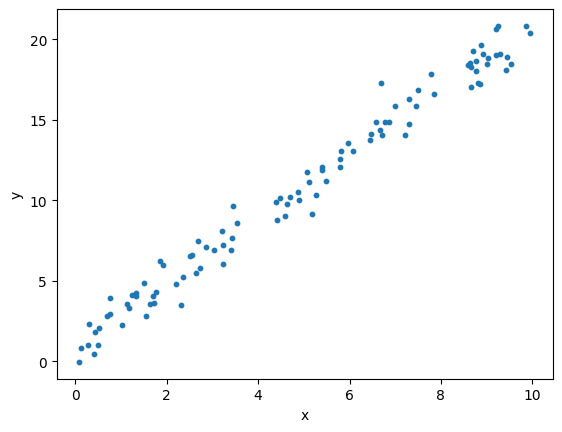

In [12]:
X = torch.rand(100) * 10
Y = 2 * X + 1 + torch.randn(100)     # true line: w = 2, b = 1, plus noise

plt.scatter(X, Y, s=10)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [13]:
w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)
lr = 0.02   # learning rate: how big each step is

for step in range(1000):
    Y_pred = w * X + b                    # 1. forward
    loss = ((Y_pred - Y) ** 2).mean()     # 2. loss (mean squared error)
    loss.backward()                       # 3. backward

    with torch.no_grad():                 # 4. update (no_grad: this step shouldn't be recorded)
        w -= lr * w.grad
        b -= lr * b.grad

    w.grad.zero_()                        # 5. zero the gradients
    b.grad.zero_()

    if step % 200 == 0:
        print(f"step {step:4d}  loss {loss.item():6.3f}  w {w.item():.2f}  b {b.item():.2f}")

print(f"learned: w = {w.item():.2f}, b = {b.item():.2f}")

step    0  loss 152.124  w 2.84  b 0.43
step  200  loss  0.756  w 2.00  b 0.86
step  400  loss  0.755  w 2.00  b 0.92
step  600  loss  0.755  w 1.99  b 0.93
step  800  loss  0.755  w 1.99  b 0.93
learned: w = 1.99, b = 0.93


These five steps are the core of training *every* neural network, from this line to large language models. PyTorch gives us tools so we don't have to write them by hand:

- `nn.Module` holds the model's parameters (instead of loose `w` and `b`)
- `nn.MSELoss`, `nn.CrossEntropyLoss`, ... compute the loss
- optimizers in `torch.optim` do the update and the zeroing: `optimizer.step()` and `optimizer.zero_grad()`

Here is the same fit with these tools. Zeroing the gradients *before* `backward()` does the same job as zeroing them at the end; this is the order you'll usually see.

In [14]:
model = nn.Linear(1, 1)                  # holds w and b for us
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.02)

for step in range(1000):
    Y_pred = model(X.unsqueeze(1))       # nn.Linear expects [batch, features]
    loss = loss_fn(Y_pred, Y.unsqueeze(1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"learned: w = {model.weight.item():.2f}, b = {model.bias.item():.2f}")

learned: w = 1.99, b = 0.93


## 3. A neural network on MNIST

MNIST has 70,000 grayscale images (28×28 pixels) of handwritten digits. Our goal: predict the digit.

`torchvision` downloads it for us. The `transform` runs on every image as it's loaded:
- `ToImage` + `ToDtype` turn it into a float tensor of shape `[1, 28, 28]` with values in [0, 1]
- `Normalize` shifts it to mean ≈ 0 and std ≈ 1 (0.1307 and 0.3081 are MNIST's mean and std). Networks train better on inputs of this scale.

In [15]:
from torchvision import datasets
from torchvision.transforms import v2 as transforms

transform = transforms.Compose([
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.MNIST(root="data", train=False, download=True, transform=transform)
print(len(train_data), "training images,", len(test_data), "test images")

image, label = train_data[0]
print(image.shape, label)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.06MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 313kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.11MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.76MB/s]

60000 training images, 10000 test images
torch.Size([1, 28, 28]) 5


A `DataLoader` serves the data in **batches** and reshuffles the training set every epoch. Training on batches is much faster than one image at a time and gives more stable gradients.

In [16]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=256)

images, labels = next(iter(train_loader))
print(images.shape)   # [batch, channels, height, width]
print(labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])


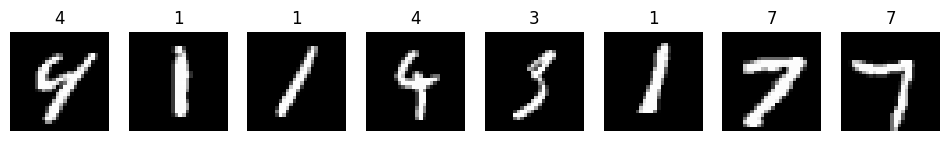

In [17]:
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img, lbl in zip(axes, images, labels):
    ax.imshow(img.squeeze(), cmap="gray")   # squeeze: [1, 28, 28] -> [28, 28]
    ax.set_title(lbl.item())
    ax.axis("off")
plt.show()

### Defining a model with `nn.Module`

Every PyTorch model is a class that inherits from `nn.Module` and defines two methods:

- `__init__`: create the layers. Layers with weights, like `nn.Linear`, register their parameters automatically, so the optimizer can find them later.
- `forward`: describe how an input flows through the layers.

Our network flattens each image into 784 numbers, passes them through a hidden layer of 128 neurons with a ReLU, and ends with 10 outputs, one score per digit.

In [18]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()                 # always call this first
        self.flatten = nn.Flatten()        # [B, 1, 28, 28] -> [B, 784]
        self.fc1 = nn.Linear(28 * 28, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

We use the model like a function: `model(x)` runs `forward` (plus some PyTorch bookkeeping, so don't call `forward` directly).

In [19]:
model = MLP().to(device)
print(model)

num_params = sum(p.numel() for p in model.parameters())
print(f"{num_params:,} parameters")

out = model(images.to(device))
print(out.shape)    # one score per class for each of the 64 images

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
101,770 parameters
torch.Size([64, 10])


### Loss and optimizer

For classification we use **cross-entropy loss**. It takes the raw scores (called *logits*) and applies softmax internally, which is why our model doesn't end with a softmax. **Adam** is an optimizer that adapts the step size for each parameter; it usually works well out of the box.

In [20]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

### The training loop

The same steps as in the line fit, now repeated over batches. One pass over the whole training set is called an **epoch**.

`model.train()` and `model.eval()` switch certain layers (like dropout, which we'll meet in the next notebook) between training and evaluation behaviour. Our MLP has none of those, but it's a good habit.

In [21]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)           # forward
        loss = loss_fn(outputs, labels)   # loss
        optimizer.zero_grad()             # zero old gradients
        loss.backward()                   # backward
        optimizer.step()                  # update the weights

        total_loss += loss.item()
    return total_loss / len(loader)

In [22]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():                 # no gradients needed: faster and uses less memory
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item()
            correct += (outputs.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader), correct / len(loader.dataset)

To keep things simple we evaluate on the test set after every epoch. In the next notebook we'll do it properly, with a separate validation set.

In [23]:
train_losses, test_losses = [], []
for epoch in range(3):
    train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
    test_loss, test_acc = evaluate(model, test_loader, loss_fn)
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    print(f"epoch {epoch + 1}: train loss {train_loss:.3f} | test loss {test_loss:.3f} | test acc {test_acc:.1%}")

epoch 1: train loss 0.261 | test loss 0.127 | test acc 96.2%
epoch 2: train loss 0.110 | test loss 0.099 | test acc 97.0%
epoch 3: train loss 0.077 | test loss 0.089 | test acc 97.2%


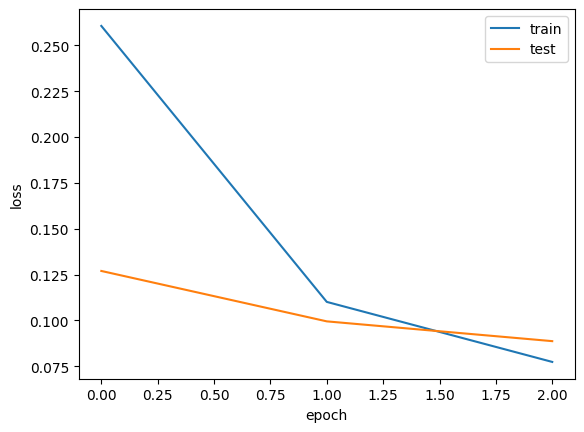

In [24]:
plt.plot(train_losses, label="train")
plt.plot(test_losses, label="test")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

Let's see some predictions (green = correct, red = wrong):

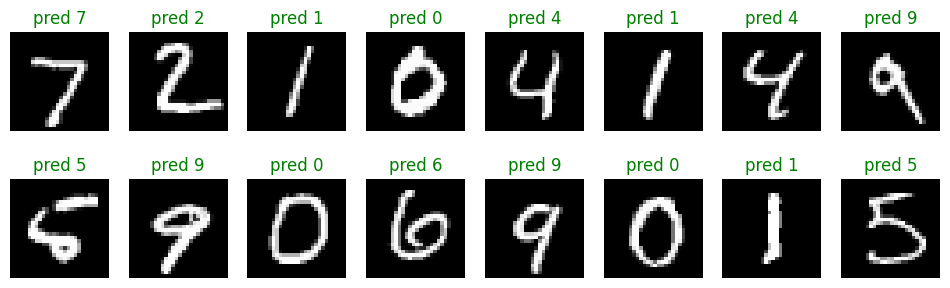

In [25]:
images, labels = next(iter(test_loader))
with torch.no_grad():
    preds = model(images.to(device)).argmax(dim=1).cpu()   # back to CPU for plotting

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, lbl, pred in zip(axes.flat, images, labels, preds):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"pred {pred.item()}", color="green" if pred == lbl else "red")
    ax.axis("off")
plt.show()

### 🖐 Your turn (optional)

1. Add a second hidden layer (128 → 64) to `MLP`. Does test accuracy improve?
2. Train with learning rates `1e-1` and `1e-5`. What happens to the loss?

Re-create the model and the optimizer before training again, otherwise you continue training the old model.

<details>
<summary>Hints</summary>

1. In `__init__`, add `self.fc2 = nn.Linear(128, 64)` and make the output layer `nn.Linear(64, 10)`. In `forward`, apply a ReLU after the new layer too.
2. Too large: the loss jumps around or gets stuck. Too small: the loss barely moves.
</details>

## Recap

- **Tensors** have a shape, dtype and device. Most bugs are shape mismatches, so print shapes often.
- **Autograd** computes gradients for us with `.backward()`.
- **Models** subclass `nn.Module`: layers in `__init__`, computation in `forward`.
- **Training** = forward → loss → zero_grad → backward → step, repeated over batches and epochs.

**Next time:** our MLP flattens each image into a long list of pixels, so it has no idea which pixels are neighbours; move a digit a few pixels to the side and the input looks completely different to it. *Convolutional* neural networks fix this by looking at small local patches of the image.